Page numbers are the printed pages of University Physics Vol. 1 and Vol. 2 in 00_books. In the PDF, add 12 (p. 513 is PDF page 525).

## Exercise 1: Field on the axis of a current loop

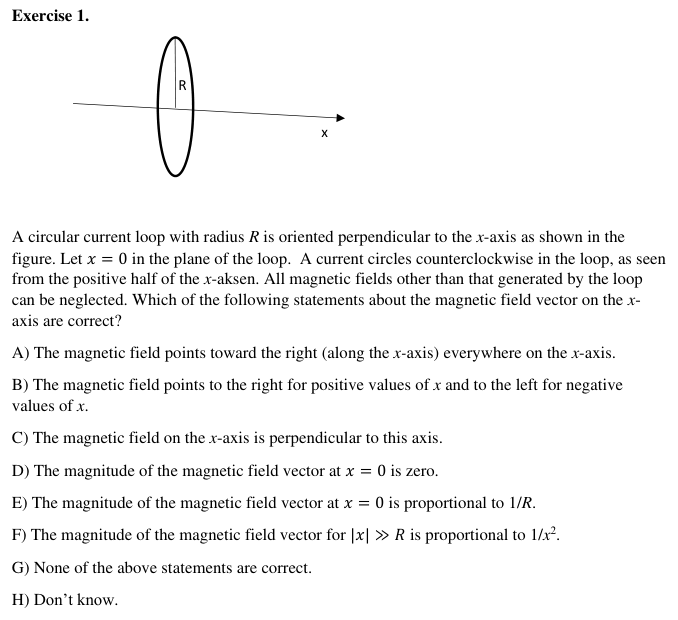

Book: University Physics Vol. 2, Section 12.4 Magnetic Field of a Current Loop (p. 511).

1. Field on the axis, Eq. 12.15 (p. 513), with the book's $y$ renamed $x$: $B = \dfrac{\mu_0 I R^2}{2(x^2+R^2)^{3/2}}$, pointing along the axis. The parts perpendicular to the axis cancel in pairs (p. 512).
2. Direction: RHR-2 (p. 480). Curl the fingers along the current and the thumb points along the field through the loop. Counterclockwise seen from $+x$ means the thumb points to $+x$. Eq. 12.15 depends only on $x^2$, so the field is the same on both sides.
3. Center, Eq. 12.17 (p. 513): $B(0) = \mu_0 I/(2R)$. Far away, Eq. 12.19 (p. 513): $B = \mu_0 \mu/(2\pi |x|^3)$.

The code checks the scaling with $I = 1$ A and $R = 1$ m.

In [1]:
import math

mu0 = 4 * math.pi * 1e-7    # T m/A
I = 1.0                     # A

def B(x, R=1.0):            # x and R in m
    return mu0 * I * R**2 / (2 * (x**2 + R**2)**1.5)

print(f"B(-2R) = {B(-2):.3g} T,  B(+2R) = {B(2):.3g} T")
print(f"B(0) = {B(0):.3g} T,  mu0 I/(2R) = {mu0 * I / 2:.3g} T")
print(f"B(0) with R = 2 m divided by B(0) with R = 1 m: {B(0, 2) / B(0, 1):.3g}")
print(f"B(100R) / B(200R) = {B(100) / B(200):.3g}")

B(-2R) = 5.62e-08 T,  B(+2R) = 5.62e-08 T
B(0) = 6.28e-07 T,  mu0 I/(2R) = 6.28e-07 T
B(0) with R = 2 m divided by B(0) with R = 1 m: 0.5
B(100R) / B(200R) = 8


Answer: A) and E) are correct.

- A) Yes. The field points along $+x$ on both sides of the loop (the axis is one straight field line, Figure 12.12), so B) is wrong.
- C) No, on the axis only the component along the axis survives.
- D) No, $B(0) = \mu_0 I/(2R) \neq 0$. E) Yes, doubling $R$ halves $B(0)$.
- F) No. Far away the loop is a dipole and $B \propto 1/x^3$: doubling $x$ divides $B$ by 8, not 4.

## Exercise 2: Proton dipole in a solenoid

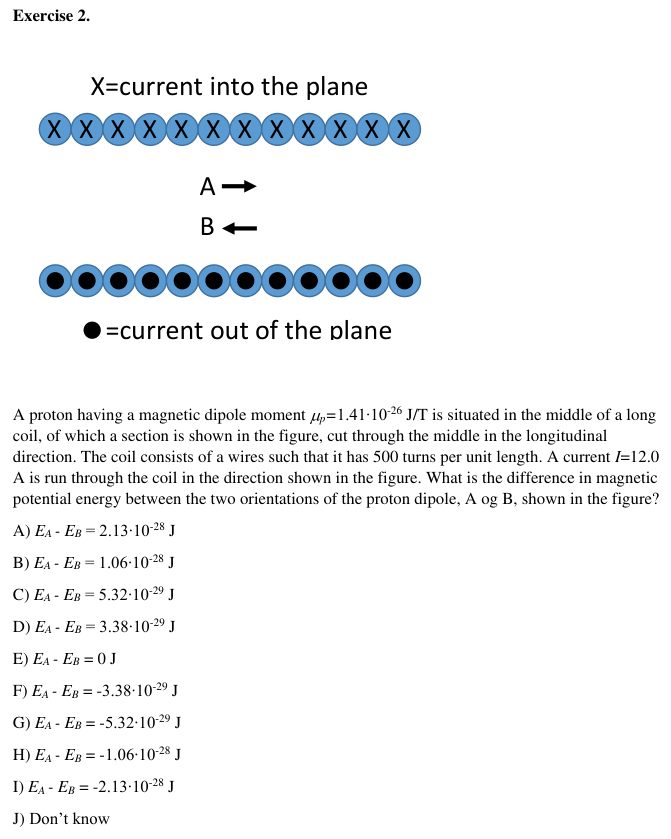

Book: University Physics Vol. 2.

1. Field inside a long solenoid, Eq. 12.30 (p. 522): $B = \mu_0 n I$. Direction with the right-hand rule on p. 522: curl the fingers along the current and the thumb points along $\vec B$ inside. Current into the page on top and out of the page at the bottom gives $\vec B$ pointing left.
2. Energy of a dipole, Eq. 11.23 (p. 481): $U = -\vec\mu\cdot\vec B$. A points right, against $\vec B$: $E_A = +\mu B$. B points left, along $\vec B$: $E_B = -\mu B$. So $E_A - E_B = 2\mu B$.

$n = 500$ turns per meter.

In [2]:
import math

mu0 = 4 * math.pi * 1e-7    # T m/A
mu_p = 1.41e-26             # J/T
n = 500                     # turns/m
I = 12.0                    # A

B = mu0 * n * I
dE = 2 * mu_p * B
print(f"B = {B:.3g} T")
print(f"EA - EB = {dE:.3g} J")

B = 0.00754 T
EA - EB = 2.13e-28 J


Answer: A) $E_A - E_B = 2.13\cdot10^{-28}$ J

A is antiparallel to the field, so it has the higher energy. With $\vec B$ pointing right (sign slip) you get I), and without the factor 2 you get B).

## Exercise 3: Loop in a growing magnetic field

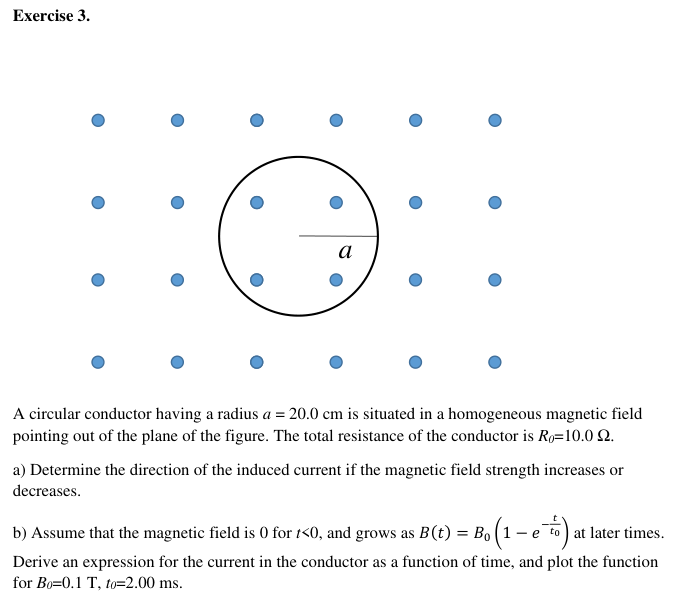

Book: University Physics Vol. 2.

1. Flux, Eq. 13.1 (p. 547): $\vec B$ is uniform and perpendicular to the loop, so $\Phi_m = B\,\pi a^2$.
2. Faraday's law, Eq. 13.2 (p. 547): $\varepsilon = -d\Phi_m/dt$. The current follows from Ohm's law, $I = |\varepsilon|/R_0$, as in Example 13.1 (p. 548).
3. Direction: Lenz's law (p. 550). The induced current makes a field that opposes the change in flux, and RHR-2 (p. 480) turns that field into a current direction.

I(0) = 0.628 A


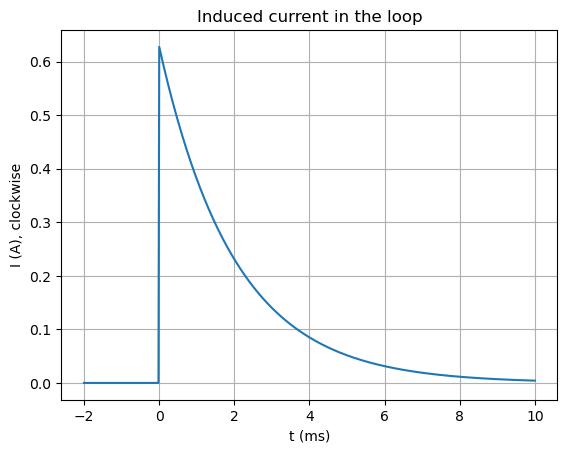

In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt

a = 0.200       # m
R0 = 10.0       # ohm
B0 = 0.1        # T
t0 = 2.00e-3    # s

I_start = math.pi * a**2 * B0 / (t0 * R0)
print(f"I(0) = {I_start:.3g} A")

t = np.linspace(-2e-3, 10e-3, 600)    # s
I = np.where(t < 0, 0, I_start * np.exp(-t / t0))

plt.plot(t * 1e3, I)
plt.xlabel("t (ms)")
plt.ylabel("I (A), clockwise")
plt.title("Induced current in the loop")
plt.grid(True)
plt.show()

a) $\vec B$ points out of the page. If $B$ increases, the induced field must point into the page inside the loop, so the current runs clockwise. If $B$ decreases, it runs counterclockwise.

b) $\Phi_m = \pi a^2 B_0\,(1 - e^{-t/t_0})$, so $d\Phi_m/dt = \dfrac{\pi a^2 B_0}{t_0}e^{-t/t_0}$ and

$$I(t) = \frac{\pi a^2 B_0}{t_0 R_0}\,e^{-t/t_0}\quad (t > 0), \qquad I(t) = 0\quad (t < 0),$$

clockwise, since $B$ grows. The current jumps to $I(0) \approx 0.628$ A at $t = 0$, where $dB/dt$ jumps from $0$ to $B_0/t_0$, and then dies out with time constant $t_0$.

## Exercise 4: Small loop inside an AC loop

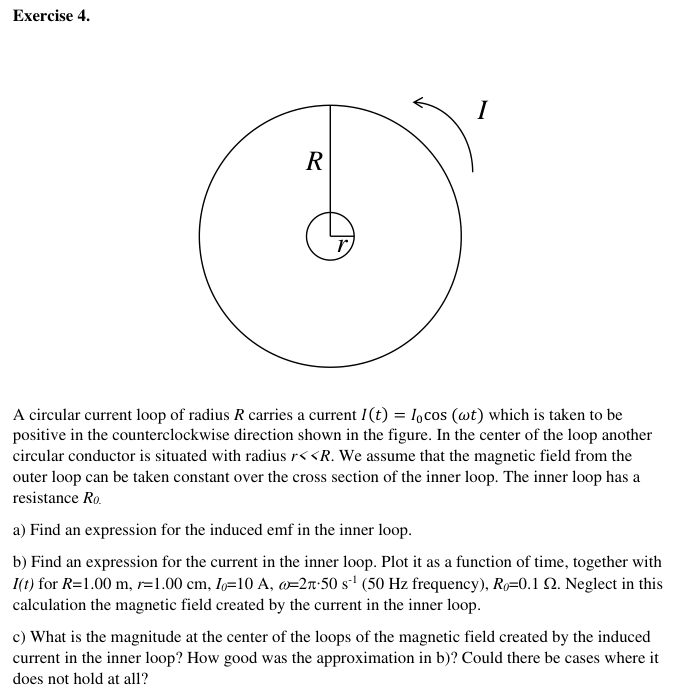

Book: University Physics Vol. 2.

1. Field at the center of the big loop, Eq. 12.17 (p. 513): $B = \mu_0 I/(2R)$, out of the page when $I > 0$.
2. Flux through the small loop, Eq. 13.1 (p. 547), with $B$ constant over it: $\Phi_m = \pi r^2 \mu_0 I(t)/(2R)$.
3. Faraday's law, Eq. 13.2 (p. 547): $\varepsilon = -d\Phi_m/dt$, then $I_{ind} = \varepsilon/R_0$. Counterclockwise is positive in both loops.
4. c) Field of the induced current at the center: Eq. 12.17 again, with $r$ and $I_{ind}$.

a) emf amplitude = 6.2e-07 V
b) I_ind amplitude = 6.2e-06 A
c) B_ind = 3.9e-10 T,  B_outer = 6.28e-06 T,  ratio = 6.2e-05


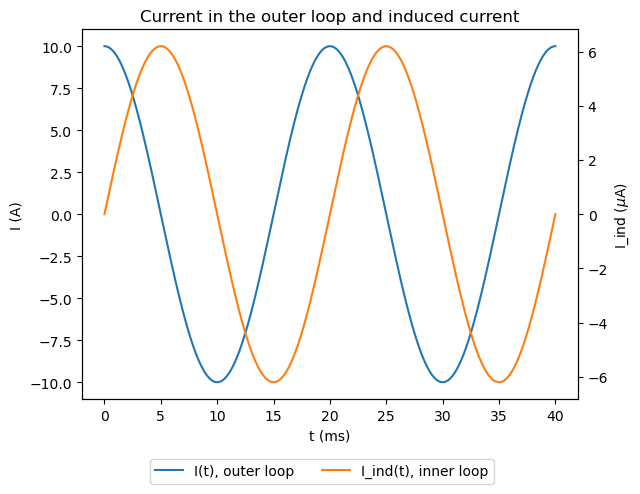

In [4]:
import math
import numpy as np
import matplotlib.pyplot as plt

mu0 = 4 * math.pi * 1e-7    # T m/A
R = 1.00                    # m
r = 0.0100                  # m
I0 = 10                     # A
w = 2 * math.pi * 50        # 1/s
R0 = 0.1                    # ohm

emf0 = mu0 * math.pi * r**2 * I0 * w / (2 * R)   # V, amplitude
Iind0 = emf0 / R0                                # A, amplitude
B_outer = mu0 * I0 / (2 * R)                     # T, at the center
B_ind = mu0 * Iind0 / (2 * r)                    # T, at the center

print(f"a) emf amplitude = {emf0:.3g} V")
print(f"b) I_ind amplitude = {Iind0:.3g} A")
print(f"c) B_ind = {B_ind:.3g} T,  B_outer = {B_outer:.3g} T,  ratio = {B_ind / B_outer:.3g}")

t = np.linspace(0, 0.04, 800)    # s, two periods
fig, ax1 = plt.subplots()
ax1.plot(t * 1e3, I0 * np.cos(w * t), "C0", label="I(t), outer loop")
ax1.set_xlabel("t (ms)")
ax1.set_ylabel("I (A)")
ax2 = ax1.twinx()
ax2.plot(t * 1e3, Iind0 * np.sin(w * t) * 1e6, "C1", label="I_ind(t), inner loop")
ax2.set_ylabel(r"I_ind ($\mu$A)")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2)
plt.title("Current in the outer loop and induced current")
plt.show()

a) $\varepsilon(t) = -\dfrac{d}{dt}\left(\dfrac{\mu_0 \pi r^2 I_0\cos\omega t}{2R}\right) = \dfrac{\mu_0 \pi r^2 I_0\,\omega}{2R}\sin\omega t$, amplitude $6.20\cdot10^{-7}$ V.

b) $I_{ind}(t) = \dfrac{\mu_0 \pi r^2 I_0\,\omega}{2R R_0}\sin\omega t$, amplitude $6.20\ \mu$A. It is a quarter period out of step with $I(t)$: it peaks when $I$ passes through zero, where $I$ changes fastest.

c) $B_{ind} = \mu_0 I_{ind}/(2r) \approx 3.90\cdot10^{-10}$ T, against $6.28\cdot10^{-6}$ T from the outer loop, a ratio of $6.2\cdot10^{-5}$. Neglecting it was a very good approximation.
The ratio is $\mu_0\pi r\omega/(2R_0) = \omega L/R_0$, with $L \approx \mu_0\pi r/2$ a rough self-inductance of the small loop (Section 14.2, p. 595). At high frequency or very low resistance (a superconducting ring) $\omega L$ is no longer small compared with $R_0$, and the self-induced emf $-L\,dI_{ind}/dt$ (Eq. 14.10, p. 596) must be included.

## Exercise 5: Turning a small loop in a big loop

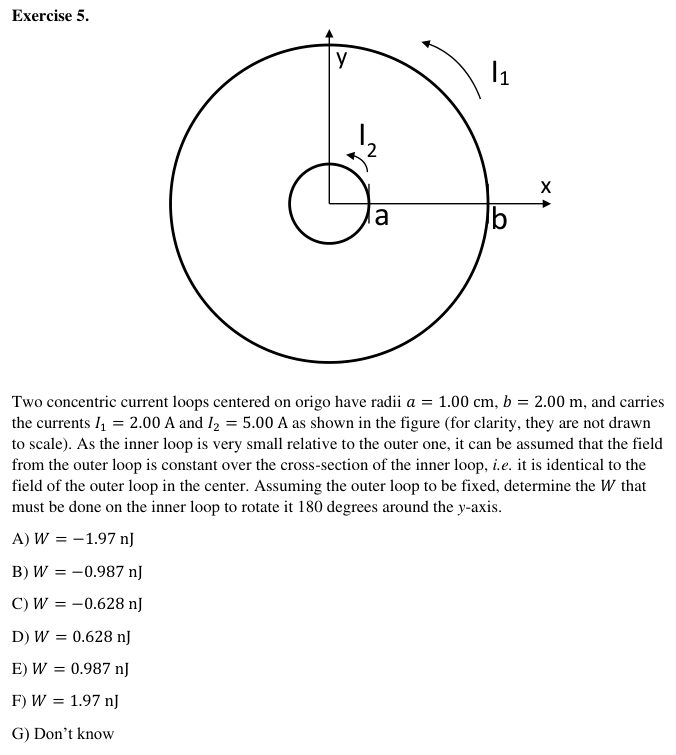

Book: University Physics Vol. 2.

1. Field of the outer loop ($I_1$, radius $b$) at the center, Eq. 12.17 (p. 513): $B = \mu_0 I_1/(2b)$, out of the page because $I_1$ runs counterclockwise.
2. Moment of the inner loop ($I_2$, radius $a$), Eq. 11.20 (p. 480): $\mu = I_2\,\pi a^2$, also out of the page ($I_2$ counterclockwise, RHR-2).
3. Energy, Eq. 11.23 (p. 481): $U = -\vec\mu\cdot\vec B$. At the start $\vec\mu$ is parallel to $\vec B$, so $U_i = -\mu B$. After 180° about the $y$-axis $\vec\mu$ points into the page, so $U_f = +\mu B$. The work needed is $W = U_f - U_i = 2\mu B$.

In [5]:
import math

mu0 = 4 * math.pi * 1e-7    # T m/A
a = 0.0100                  # m, inner loop
b = 2.00                    # m, outer loop
I1 = 2.00                   # A, outer loop
I2 = 5.00                   # A, inner loop

B = mu0 * I1 / (2 * b)
mu = I2 * math.pi * a**2
W = 2 * mu * B
print(f"B = {B:.3g} T,  mu = {mu:.3g} A m^2")
print(f"W = {W * 1e9:.3g} nJ")

B = 6.28e-07 T,  mu = 0.00157 A m^2
W = 1.97 nJ


Answer: F) $W = 1.97$ nJ

$W > 0$ because the loop starts in its lowest-energy orientation (moments parallel) and ends in the highest. Without the factor 2 you get E) 0.987 nJ, and the straight-wire field $\mu_0 I_1/(2\pi b)$ instead of the loop field gives D) 0.628 nJ.